# The headline gap: classical models and dataset bias

This project examines a gap between performance on a news dataset and performance on different headlines. The aim is to compare classifiers and understand what their scores say about generalization.

This first notebook contains the machine learning workflow: data exploration, text preparation, TF-IDF, model selection and evaluation. It compares XGBoost, LinearSVC and MLP on titles plus article bodies, then trains a headline-only LinearSVC for the comparison with DistilBERT in notebook 2.

## Research questions

1. **RQ1:** Which dataset patterns could act as shortcuts instead of indicating factual truth?
2. **RQ2:** Do classical TF-IDF models retain their performance on external headlines?
3. **RQ3:** Does fine-tuned DistilBERT improve on the headline-only TF-IDF baseline, and which limitations remain?

The EDA and linear coefficients address RQ1. The internal/custom evaluation addresses RQ2. The headline-only baseline establishes the reference for RQ3, which notebook 2 completes. All models use the same row partitions and the same 40 custom headlines.

## Environment setup

Use Python 3.11 in a project environment. The first check below prints the Python executable used by this notebook and checks package versions before the analysis imports.

| Environment | Installation | Device |
|---|---|---|
| Local, notebook 1 | `%pip install -r ../requirements-ml.txt` when launched from `notebooks/` | CPU |
| Local, notebook 2 | Install CPU PyTorch, then `%pip install -r ../requirements.txt` | CPU by default when CUDA is absent |
| Colab | Install from the repository's requirements file; keep its CUDA-enabled PyTorch | Select a GPU runtime for DistilBERT |

If launched from the repository root, remove `../` from these commands. `%pip` installs in the current notebook kernel. After installing or changing training libraries, **restart the kernel/runtime and run from the first cell**. Executing an import cell again can leave cached dependency checks from the old session.

The complete [environment guide](../docs/environment.md) includes Windows/Conda commands, CPU PyTorch installation, the Colab workflow and checkpoint transfer. The first notebook has no dependency on PyTorch or Transformers.

In [ ]:
import sys
from importlib.metadata import PackageNotFoundError, version

print(f'Python: {sys.version.split()[0]}')
print(f'Executable: {sys.executable}')
if sys.version_info < (3, 10):
    raise RuntimeError('Use Python 3.10 or later; Python 3.11 is recommended for this project.')

try:
    from packaging.specifiers import SpecifierSet
except ModuleNotFoundError as error:
    raise ModuleNotFoundError('Install requirements in this kernel, then restart it.') from error

requirements = {'pandas': '>=2,<3', 'numpy': '>=1.24,<3', 'matplotlib': '>=3.7,<4', 'seaborn': '>=0.12,<1', 'scikit-learn': '>=1.3,<2', 'nltk': '>=3.8,<4', 'xgboost': '>=2,<4', 'kagglehub': '>=1.0.3,<2'}
problems = []
for package, allowed in requirements.items():
    try:
        installed = version(package)
        print(f'{package}: {installed}')
        if installed not in SpecifierSet(allowed):
            problems.append(f'{package} {allowed} required; found {installed}')
    except PackageNotFoundError:
        problems.append(f'{package} is missing')
if problems:
    raise RuntimeError('Environment check failed: ' + '; '.join(problems) +
        '. Install the requirements file for this notebook with %pip, restart the kernel, and run from the first cell.')

In [12]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
from collections import Counter
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
)

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import json
from pathlib import Path

USE_COLAB = False
if USE_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/fake-news-project')
else:
    PROJECT_ROOT = Path.cwd().resolve()
    if PROJECT_ROOT.name == 'notebooks':
        PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / 'notebooks').is_dir():
    raise FileNotFoundError('Set PROJECT_ROOT to the repository folder.')

SEED = 42
DATA_DIR = PROJECT_ROOT / 'data' / 'raw'
CUSTOM_PATH = PROJECT_ROOT / 'data' / 'evaluation' / 'custom_headlines.json'
FIGURES_DIR = PROJECT_ROOT / 'results' / 'figures' / '01_classical_ml'
METRICS_DIR = PROJECT_ROOT / 'results' / 'metrics' / '01_classical_ml'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(name):
    plt.gcf().savefig(FIGURES_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## Data preparation

The CSV files are loaded from `data/raw/` and downloaded through KaggleHub when missing. Labels are `0 = Fake` and `1 = Real`.

Rows with missing titles or bodies are removed. Keeping one occurrence of each exact headline prevents the same headline from appearing in multiple partitions. This leaves 38,729 articles: 17,903 Fake (46.2%) and 20,826 Real (53.8%). Near-duplicates may remain.

The raw data contain more Fake articles, but repeated titles are more frequent in that class. This explains the different class proportions after cleaning.

In [ ]:
DATASET_HANDLE = 'clmentbisaillon/fake-and-real-news-dataset'
DATA_DIR.mkdir(parents=True, exist_ok=True)
required_files = ['Fake.csv', 'True.csv']
missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]

if missing_files:
    try:
        import kagglehub
    except ModuleNotFoundError as error:
        raise ModuleNotFoundError(
            'Install KaggleHub in this notebook kernel with '
            '%pip install "kagglehub>=1.0.3,<2", then rerun this cell.'
        ) from error

    from shutil import copy2

    try:

        download_dir = Path(kagglehub.dataset_download(DATASET_HANDLE))
    except Exception as error:
        raise RuntimeError(
            'Kaggle download failed. Check the connection and the original error below. '
            'If Kaggle requests authentication, run kagglehub.login() and retry. '
            'You can also place Fake.csv and True.csv in data/raw/.'
        ) from error

    absent = [name for name in missing_files if not (download_dir / name).is_file()]
    if absent:
        raise FileNotFoundError(f'Expected CSV files not found in {download_dir}: {absent}')

    for name in missing_files:
        copy2(download_dir / name, DATA_DIR / name)
    print(f'Dataset ready in {DATA_DIR}')
else:
    print(f'Using existing CSV files in {DATA_DIR}')

fake = pd.read_csv(DATA_DIR / 'Fake.csv')
true = pd.read_csv(DATA_DIR / 'True.csv')

for name, frame in [('Fake.csv', fake), ('True.csv', true)]:
    missing_columns = {'title', 'text'} - set(frame.columns)
    if missing_columns:
        raise ValueError(f'{name} is missing required columns: {sorted(missing_columns)}')

fake['label'] = 0
true['label'] = 1

In [14]:
df = pd.concat([fake, true], ignore_index=True)
df = df[['title', 'text', 'label']].dropna().copy()

df = df.drop_duplicates(subset=['title']).reset_index(drop=True)
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

df.head(3)

,title,text,label
0,Supreme Court Justice Ginsburg 'regrets' Trump...,WASHINGTON (Reuters) - U.S. Supreme Court Just...,1
1,DOZENS Of GOP Foreign Policy Experts Pledge T...,Over sixty GOP national security buffs have ta...,0
2,REPORT: Trump Laughed After Woman Was Grabbed...,Donald Trump is again under fire from allegati...,0


## Lemmatization

WordNet lemmatization groups some inflected forms. The default lemmatizer assumes nouns, so it does not systematically reduce verbs such as `running` to `run`. Title and body are then combined in `full_text`.

In [15]:
lemmatizer = WordNetLemmatizer()
def lemmatize_words(text):
    return " ".join([lemmatizer.lemmatize(word) for word in text.split()])

df["lemmatized_title"] = df["title"].apply(lambda text : lemmatize_words(text))
df["lemmatized_text"] = df["text"].apply(lambda text : lemmatize_words(text))

In [16]:
df["full_text"] = df["lemmatized_title"] + " " + df["lemmatized_text"]

## Cleaning checks

Check for remaining duplicate rows and missing values after the shared preparation step.

In [17]:
print(f"Duplicate values before cleaning: {df.duplicated().sum()}")

df = df.drop_duplicates().reset_index(drop=True)
df = df.dropna().reset_index(drop=True)

print(f"Duplicate values after cleaning: {df.duplicated().sum()}")

Duplicate values before cleaning: 0
Duplicate values after cleaning: 0


## RQ1: dataset patterns

Compare punctuation, frequent words and text length between the classes. Differences in publisher names, image credits or reporting style may help predict dataset labels without indicating whether an article is true.

The EDA identifies possible cues. Later, LinearSVC coefficients show which terms are associated with the fitted decision rule.

### Class distribution

After deduplication, the class proportions are 46.2% Fake and 53.8% Real. Report both classes when evaluating errors, even though the imbalance is modest.

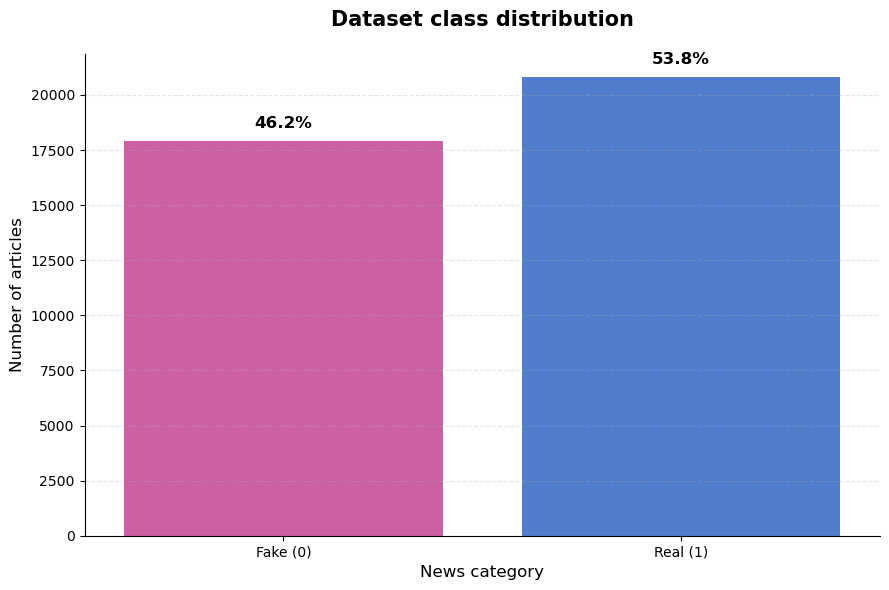

In [18]:
my_palette = {0: "#de4ea7", 1: "#3e77e1"}

plt.figure(figsize=(9, 6))

ax = sns.countplot(x='label', data=df, palette=my_palette, hue='label', legend=False)

plt.title('Dataset class distribution', fontweight='bold', fontsize=15, pad=20)
plt.xlabel('News category', fontsize=12)
plt.ylabel('Number of articles', fontsize=12)
plt.xticks([0, 1], ['Fake (0)', 'Real (1)'])

total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom',
                fontsize=12, fontweight='bold', xytext=(0, 7),
                textcoords='offset points')

sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
save_figure('class_distribution')
plt.show()

> Similar class sizes do not remove differences in sources, topics or writing style.

### Punctuation

Compare relative frequencies of punctuation in headlines and article bodies. These are properties of this collection, rather than general rules for detecting false claims.

In [19]:
def punct_frequency(dataframe, top_pos):
    cnt = Counter()
    for text in dataframe.values:

        all_punct = re.findall(r"[^\w\s]", str(text))
        for punct in all_punct:
            cnt[punct] += 1

    dict = {}

    for punct, count in cnt.most_common(top_pos):
        dict[punct] = count
    return dict

In [20]:
def plot_punct_freq(dict_fake, dict_true, title):

    puncts = list(set(dict_fake.keys()) | set(dict_true.keys()))
    fake_counts = {p: dict_fake.get(p, 0) for p in puncts}
    true_counts = {p: dict_true.get(p, 0) for p in puncts}

    f_total, t_total = sum(fake_counts.values()), sum(true_counts.values())
    fake_rel = {p: c / f_total for p, c in fake_counts.items() if f_total > 0}
    true_rel = {p: c / t_total for p, c in true_counts.items() if t_total > 0}

    combined = {p: fake_rel.get(p, 0) + true_rel.get(p, 0) for p in puncts}
    ordered_puncts = sorted(combined, key=combined.get, reverse=True)

    fake_values = [fake_rel.get(p, 0) for p in ordered_puncts]
    true_values = [true_rel.get(p, 0) for p in ordered_puncts]

    x, width = np.arange(len(ordered_puncts)), 0.35
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.bar(x - width/2, fake_values, width, label='Fake', color="#de4ea7", alpha=0.9, edgecolor='white')
    ax.bar(x + width/2, true_values, width, label='True', color="#3e77e1", alpha=0.9, edgecolor='white')

    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_ylabel('Relative frequency')
    ax.set_xticks(x)
    ax.set_xticklabels(ordered_puncts, fontsize=12)
    ax.legend()
    ax.yaxis.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    save_figure(re.sub(r'[^a-z0-9]+', '_', title.lower()).strip('_'))
    plt.show()

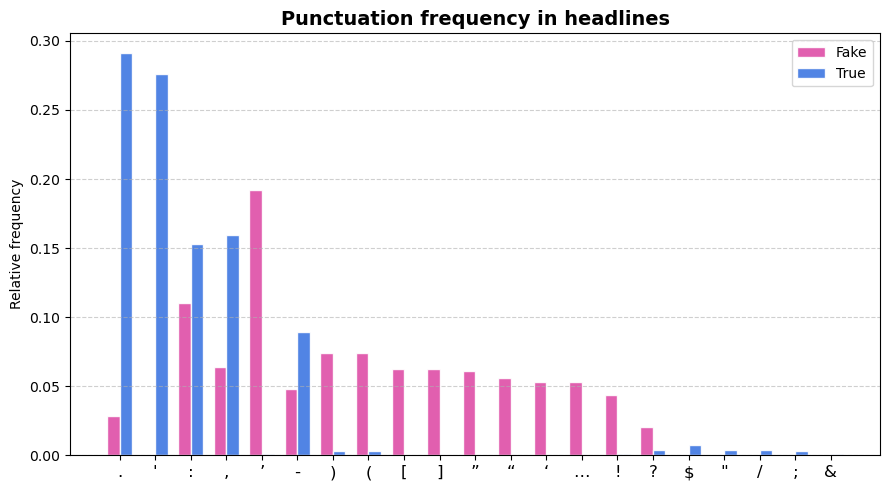

In [21]:
fake_title_punct = punct_frequency(df[df["label"] == 0]["title"], 15)

true_title_punct = punct_frequency(df[df["label"] == 1]["title"], 15)

plot_punct_freq(fake_title_punct, true_title_punct, "Punctuation frequency in headlines")

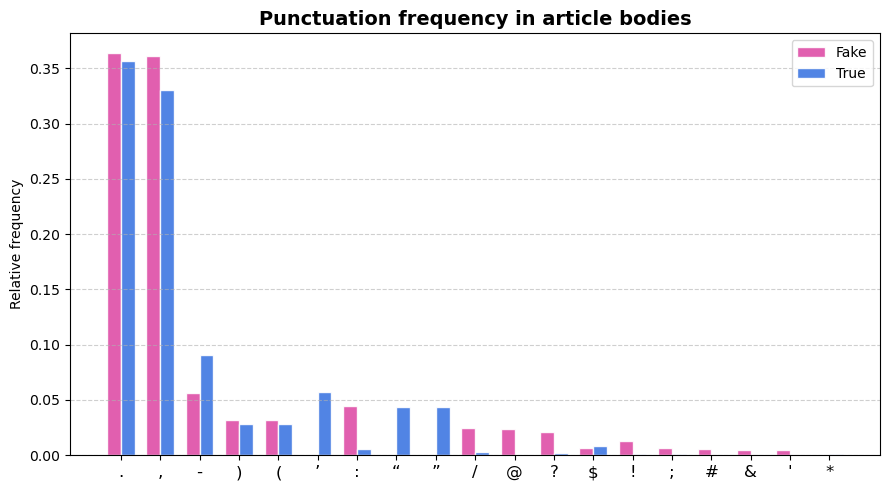

In [22]:
fake_text_punct = punct_frequency(df[df["label"] == 0]["text"], 15)

true_text_punct = punct_frequency(df[df["label"] == 1]["text"], 15)

plot_punct_freq(fake_text_punct, true_text_punct, "Punctuation frequency in article bodies")

> The classes differ in punctuation use. This supports examining their writing styles alongside vocabulary and length.

### Frequent words

Count frequent terms separately for each class. Frequencies can reveal dominant topics and publisher names, but do not measure classifier importance.

In [23]:
def word_frequency(dataframe, top_pos):
    cnt = Counter()
    for text in dataframe.values:
        if isinstance(text, str):
            for word in text.split():
                cnt[word] += 1

    dict_freq = {}

    for word, count in cnt.most_common(top_pos):
        dict_freq[word] = count
    return dict_freq

In [24]:
def plot_word_freq(dict_fake, dict_true, title):

    words = list(set(dict_fake.keys()) | set(dict_true.keys()))

    fake_counts = {w: dict_fake.get(w, 0) for w in words}
    true_counts = {w: dict_true.get(w, 0) for w in words}

    fake_total = sum(fake_counts.values())
    true_total = sum(true_counts.values())

    fake_rel = {w: c / fake_total for w, c in fake_counts.items() if fake_total > 0}
    true_rel = {w: c / true_total for w, c in true_counts.items() if true_total > 0}

    combined_rel = {w: fake_rel.get(w, 0) + true_rel.get(w, 0) for w in words}
    top_words = sorted(combined_rel, key=combined_rel.get, reverse=True)

    fake_values = [fake_rel.get(w, 0) for w in top_words]
    true_values = [true_rel.get(w, 0) for w in top_words]

    x = np.arange(len(top_words))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.bar(x - width / 2, fake_values, width, label='Fake', color="#de4ea7", alpha=0.9, edgecolor='white')
    ax.bar(x + width / 2, true_values, width, label='True', color="#3e77e1", alpha=0.9, edgecolor='white')

    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_ylabel('Relative frequency')
    ax.set_xticks(x)

    ax.set_xticklabels(top_words, rotation=45, ha='right')
    ax.legend()

    ax.yaxis.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    save_figure(re.sub(r'[^a-z0-9]+', '_', title.lower()).strip('_'))
    plt.show()

## Stopwords

For the word-frequency plots, remove English stopwords and lowercase the text. Model inputs use lemmatization, regex cleaning and the stopword filtering configured in TF-IDF.

In [25]:
STOPWORDS = set(stopwords.words('english'))

def remove_stopwords(text):
    words = text.lower().split()
    return " ".join([word for word in words if word not in STOPWORDS])

df["title_analysis"] = df["title"].apply(lambda text : remove_stopwords(text))
df["text_analysis"] = df["text"].apply(lambda text : remove_stopwords(text))

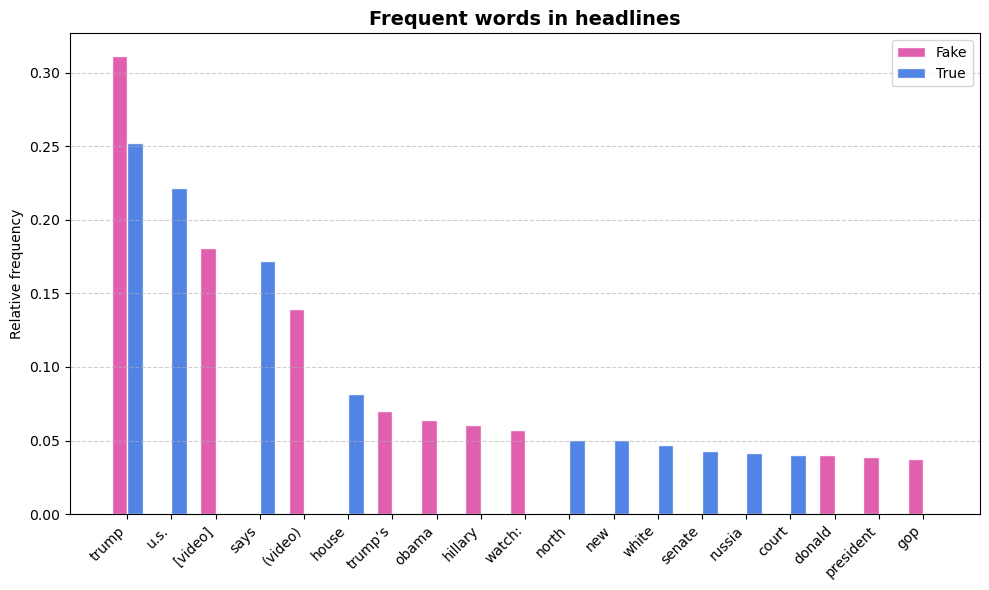

In [26]:
fake_title_word = word_frequency(df[df["label"] == 0]["title_analysis"], 10)

true_title_word = word_frequency(df[df["label"] == 1]["title_analysis"], 10)

plot_word_freq(fake_title_word, true_title_word, "Frequent words in headlines")

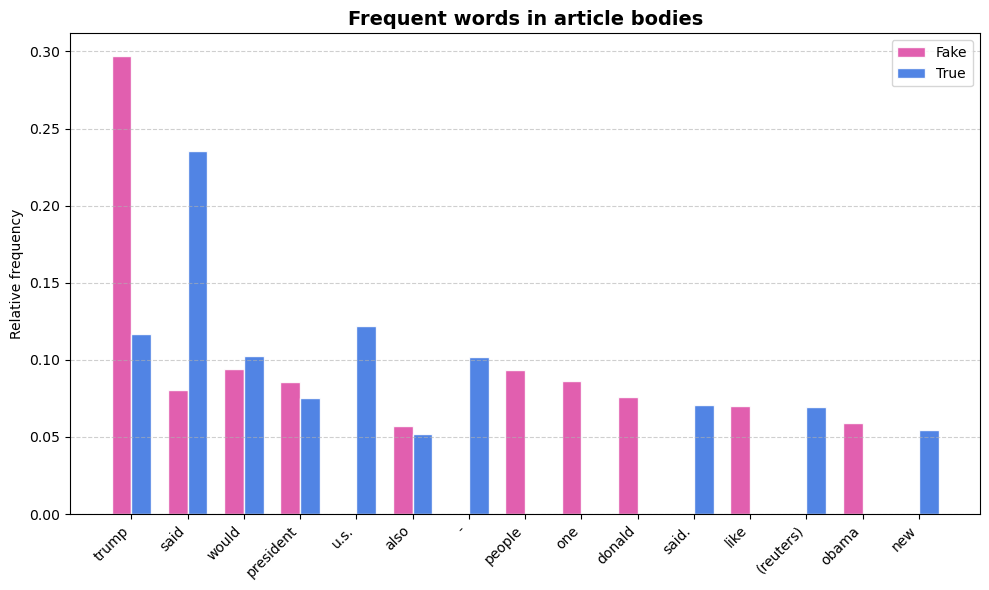

In [27]:
fake_text_word = word_frequency(df[df["label"] == 0]["text_analysis"], 10)

true_text_word = word_frequency(df[df["label"] == 1]["text_analysis"], 10)

plot_word_freq(fake_text_word, true_text_word, "Frequent words in article bodies")

> Reuters mentions and image/link references suggest that source and formatting conventions differ between the classes. The coefficient analysis revisits these observations after fitting LinearSVC.

### Text length distributions

Compare headline and body lengths across classes using medians, quartiles and outliers.

In [28]:
df["title_wc"] = df["title"].str.split().str.len()
df["text_wc"] = df["text"].str.split().str.len()

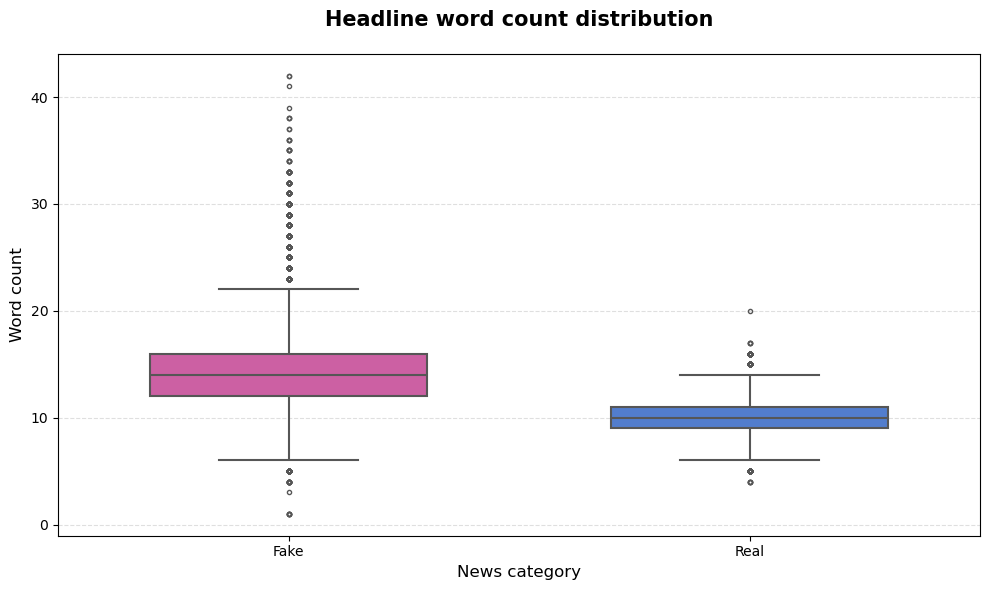

In [29]:
plt.figure(figsize=(10, 6))

ax = sns.boxplot(x='label', y='title_wc', data=df,
                 palette={0: "#de4ea7", 1: "#3e77e1"},
                 hue='label', legend=False,
                 width=0.6, linewidth=1.5, fliersize=3)

plt.title('Headline word count distribution', fontweight='bold', fontsize=15, pad=20)
plt.xlabel('News category', fontsize=12)
plt.ylabel('Word count', fontsize=12)
plt.xticks([0, 1], ['Fake', 'Real'])

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
save_figure('headline_length')
plt.show()

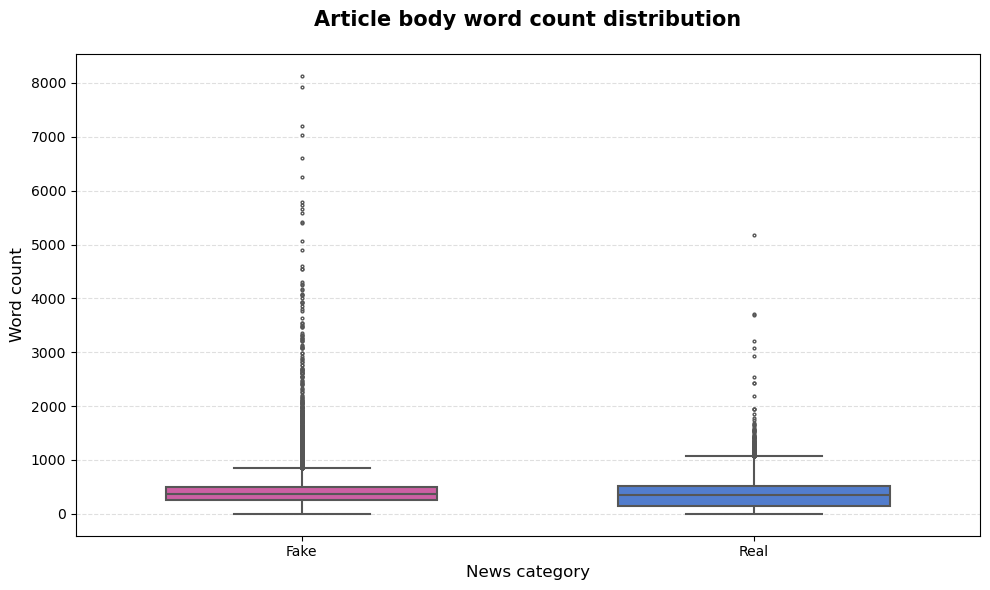

In [30]:
plt.figure(figsize=(10, 6))

ax = sns.boxplot(x='label', y='text_wc', data=df,
                 palette={0: "#de4ea7", 1: "#3e77e1"},
                 hue='label', legend=False,
                 width=0.6, linewidth=1.5, fliersize=2)

plt.title('Article body word count distribution', fontweight='bold', fontsize=15, pad=20)
plt.xlabel('News category', fontsize=12)
plt.ylabel('Word count', fontsize=12)
plt.xticks([0, 1], ['Fake', 'Real'])

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
save_figure('body_length')
plt.show()

> Length differences may reflect editorial conventions or unusual examples. Length alone does not establish whether a claim is true.

### Source markers

Publisher names can correlate with labels because of how the dataset was assembled. Removing a visible identifier does not remove every source-related pattern.

## Text cleaning

Remove the prefix ending in a Reuters dateline, parenthesized/bracketed fragments and extra whitespace. The rules are retained from the evaluated experiment.

Here the title and body are joined before cleaning. The Reuters-prefix rule can therefore remove the title when a dateline follows it in the body. Bracket removal may also discard content. These choices are limitations of preprocessing and are not tested separately in an ablation.

In [31]:
def clean_news_text(text):

    text = re.sub(r'^.*\(Reuters\)\s*-\s*', '', text)

    text = re.sub(r'\([^)]*\)', '', text)
    text = re.sub(r'\[[^\]]*\]', '', text)

    text = re.sub(r'\s+', ' ', text).strip()

    return text

df['clean_data'] = df['full_text'].apply(clean_news_text)

## RQ2: internal performance

Train XGBoost, LinearSVC and MLP on the cleaned title/body field. Grid search selects hyperparameters inside the training partition. The held-out test measures performance on articles from the same collection.

The custom headline evaluation then measures transfer to selected examples with different sources, topics and writing styles. The full-text models also receive shorter inputs there.

In [32]:
X = df["clean_data"]
y = df["label"]

## Shared data partitions

Both notebooks use the same cleaned rows and seed to create 60% training, 15% validation and 25% final test partitions. Classical models select hyperparameters through three-fold cross-validation within the training partition. DistilBERT uses the validation partition for checkpoint selection. The final test is reserved for evaluation.

TF-IDF is fitted inside each cross-validation fold through a scikit-learn pipeline.

In [33]:
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_development, y_development, test_size=0.20,
    random_state=SEED, stratify=y_development
)
split_rows = []
for partition, values in [('train', X_train), ('validation', X_val), ('test', X_test)]:
    split_rows.extend({'row_id': int(i), 'partition': partition} for i in values.index)
pd.DataFrame(split_rows).to_csv(METRICS_DIR / 'partitions.csv', index=False)

### TF-IDF representation

The next cells fit a descriptive vectorizer on the training partition to inspect vocabulary and mean weights. The model searches below fit their own vectorizers inside each cross-validation fold.

In [34]:
tfidf = TfidfVectorizer(
    max_features=1000,
    max_df=0.5,
    ngram_range=(1,2),
    stop_words=stopwords.words('english')
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

## Vocabulary inspection

The vocabulary contains up to 1,000 unigram and bigram features. Inspect sampled words and mean training weights below.

In [35]:
features = pd.DataFrame(tfidf.get_feature_names_out(), columns=['word'])

features = features.sample(frac=1, random_state=SEED).reset_index(drop=True)

for f in features['word'][:10]:
    print(f)

majority
republican party
request
power
image
prison
part
lost
support
called


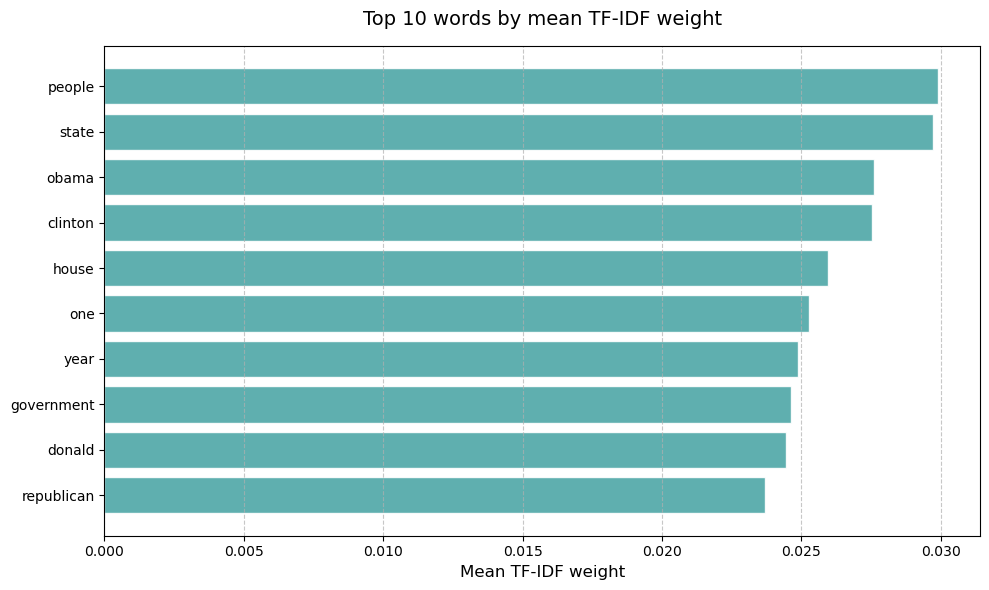

In [36]:
weights = X_train_tfidf.mean(axis=0).tolist()[0]
features = tfidf.get_feature_names_out()

weights_df = pd.DataFrame({'word': features, 'weight': weights})
weights_df = weights_df.sort_values(by='weight', ascending=False)

top_10 = weights_df.head(10).iloc[::-1]

plt.figure(figsize=(10, 6))

plt.barh(top_10['word'], top_10['weight'], color='#4da6a6', edgecolor='white', alpha=0.9)

plt.title('Top 10 words by mean TF-IDF weight', fontsize=14, pad=15)
plt.xlabel('Mean TF-IDF weight', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
save_figure('mean_tfidf_weights')
plt.show()

> Mean TF-IDF weight describes the representation, not classifier importance. The LinearSVC coefficients below provide a model-specific view.

In [37]:
model_stats = {}

def print_metrics(y_true, y_pred, model_name, exec_time, save_results):
    print(f"*** {model_name} ***")

    acc = accuracy_score(y_true, y_pred)
    print(f'Accuracy: {acc*100:.2f}%')

    prec = precision_score(y_true, y_pred, zero_division=0)
    print(f'Precision: {prec*100:.2f}%')

    recall = recall_score(y_true, y_pred, zero_division=0)
    print(f'Recall: {recall*100:.2f}%')

    f1 = f1_score(y_true, y_pred, zero_division=0)
    print(f"F1-score: {f1*100:.2f}%")

    cm = confusion_matrix(y_true, y_pred)
    print(f'Confusion Matrix:\n{cm}')
    print(f'Execution Time: {exec_time:.1f} seconds')
    print("")

    if save_results == 1:
        model_stats[model_name] = {
            'Accuracy': acc,
            'Precision': prec,
            'Recall': recall,
            'F1-Score': f1,
            'Time': exec_time,
            'Matrix': cm
        }

> Precision, recall and binary F1 use Real (`1`) as the positive class. Accuracy covers both classes. Interpret them alongside the confusion matrices.

### Hyperparameter selection

GridSearchCV selects the parameter combination with the highest mean accuracy across three training folds. This explores a limited grid and does not guarantee an optimal model.

### XGBoost

The grid varies tree count, learning rate and maximum depth, with subsampling fixed at 0.8. Three-fold cross-validation selects the configuration with the highest mean accuracy.

In [38]:
param_grid_xgb = {
    'n_estimators': [50, 100],
    'learning_rate': [0.1, 0.2],
    'max_depth': [3, 5],
    'subsample': [0.8]
}

grid_search_xgb = GridSearchCV(
    Pipeline([
        ('tfidf', TfidfVectorizer(
            max_features=1000, max_df=0.5, ngram_range=(1, 2), stop_words='english',
        )),
        ('model', XGBClassifier(
                objective='binary:logistic', eval_metric='logloss',
                random_state=SEED, n_jobs=-1,
            )),
    ]),
    param_grid={f'model__{key}': value for key, value in param_grid_xgb.items()},
    cv=3, scoring='accuracy', n_jobs=-1, verbose=0,
)

start = time.time()
grid_search_xgb.fit(X_train, y_train)
elapsed_time = time.time() - start

print(f"Best parameters: {grid_search_xgb.best_params_}")
best_xgb_pipeline = grid_search_xgb.best_estimator_
best_xgb = best_xgb_pipeline.named_steps['model']
xgb_params = {key.removeprefix('model__'): value for key, value in grid_search_xgb.best_params_.items()}

y_pred_test_xgb = best_xgb_pipeline.predict(X_test)

xgb_label = f"XGB (lr={xgb_params['learning_rate']}, depth={xgb_params['max_depth']})"

print_metrics(y_test, y_pred_test_xgb, f"{xgb_label}", elapsed_time, 1)

Best parameters: {'model__learning_rate': 0.2, 'model__max_depth': 5, 'model__n_estimators': 100, 'model__subsample': 0.8}
*** XGB (lr=0.2, depth=5) ***
Accuracy: 97.88%
Precision: 97.37%
Recall: 98.73%
F1-score: 98.05%
Confusion Matrix:
[[4337  139]
 [  66 5141]]
Execution Time: 345.7 seconds



### LinearSVC

Tune the regularization parameter C and compare L1 with L2 penalties. The linear classifier operates on sparse TF-IDF features.

In [39]:
param_grid_svc = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2']
}

grid_search_svc = GridSearchCV(
    Pipeline([
        ('tfidf', TfidfVectorizer(
            max_features=1000, max_df=0.5, ngram_range=(1, 2), stop_words='english',
        )),
        ('model', LinearSVC(random_state=SEED, max_iter=2000, dual=False)),
    ]),
    param_grid={f'model__{key}': value for key, value in param_grid_svc.items()},
    cv=3, scoring='accuracy', n_jobs=-1, verbose=0,
)

start = time.time()
grid_search_svc.fit(X_train, y_train)
elapsed_time = time.time() - start

print(f"Best parameters: {grid_search_svc.best_params_}")
best_svc_pipeline = grid_search_svc.best_estimator_
best_svc = best_svc_pipeline.named_steps['model']
svc_params = {key.removeprefix('model__'): value for key, value in grid_search_svc.best_params_.items()}

y_pred_test_svc = best_svc_pipeline.predict(X_test)

params = svc_params
svc_label = f"LinearSVC (C={params['C']}, penalty={params['penalty']})"

print_metrics(y_test, y_pred_test_svc, f"{svc_label}", elapsed_time, 1)

Best parameters: {'model__C': 1, 'model__penalty': 'l1'}
*** LinearSVC (C=1, penalty=l1) ***
Accuracy: 97.98%
Precision: 97.90%
Recall: 98.35%
F1-score: 98.12%
Confusion Matrix:
[[4366  110]
 [  86 5121]]
Execution Time: 260.1 seconds



### Multilayer perceptron

The grid varies hidden layers, L2 regularization and learning rate. The estimator reserves 10% of each training fold for early stopping, which monitors validation accuracy. TF-IDF is fitted on the outer training fold.

In [40]:
param_grid_mlp = {
    'hidden_layer_sizes': [(16,), (32,), (32, 16)],
    'alpha': [0.0001, 0.01],
    'learning_rate_init': [0.001, 0.01]
}

grid_search_mlp = GridSearchCV(
    Pipeline([
        ('tfidf', TfidfVectorizer(
            max_features=1000, max_df=0.5, ngram_range=(1, 2), stop_words='english',
        )),
        ('model', MLPClassifier(
                activation='relu', solver='adam', max_iter=50,
                early_stopping=True, validation_fraction=0.1, random_state=SEED,
            )),
    ]),
    param_grid={f'model__{key}': value for key, value in param_grid_mlp.items()},
    cv=3, scoring='accuracy', n_jobs=-1, verbose=0,
)

start = time.time()
grid_search_mlp.fit(X_train, y_train)
elapsed_time = time.time() - start

print(f"Best parameters: {grid_search_mlp.best_params_}")
best_mlp_pipeline = grid_search_mlp.best_estimator_
best_mlp = best_mlp_pipeline.named_steps['model']
mlp_params = {key.removeprefix('model__'): value for key, value in grid_search_mlp.best_params_.items()}

y_pred_test_mlp = best_mlp_pipeline.predict(X_test)

params = mlp_params
mlp_label = f"MLP (layers={params['hidden_layer_sizes']}, lr={params['learning_rate_init']})"

print_metrics(y_test, y_pred_test_mlp, f"{mlp_label}", elapsed_time, 1)

Best parameters: {'model__alpha': 0.01, 'model__hidden_layer_sizes': (16,), 'model__learning_rate_init': 0.001}
*** MLP (layers=(16,), lr=0.001) ***
Accuracy: 97.75%
Precision: 97.78%
Recall: 98.04%
F1-score: 97.91%
Confusion Matrix:
[[4360  116]
 [ 102 5105]]
Execution Time: 251.3 seconds



## Internal results

All three models are close on the internal test: LinearSVC reaches 97.98% accuracy, XGBoost 97.88% and MLP 97.75%. LinearSVC is highest in this run, but the differences are small and have not been tested across repeated runs.

The custom set below provides a different view of their performance.

## Model comparison

Compare accuracy, precision, recall, F1 and execution time. With Real as the positive class, fake articles predicted as real are false positives; real articles predicted as fake are false negatives.

In [41]:
df_stats = pd.DataFrame(model_stats).T.sort_values(by='Accuracy', ascending=False)

models = df_stats.index
x = np.arange(len(models))
width = 0.35

print("Models ranked by accuracy:")
print(df_stats['Accuracy'])

Models ranked by Accuracy:
LinearSVC (C=1, penalty=l1)     0.979758
XGB (lr=0.2, depth=5)           0.978829
MLP (layers=(16,), lr=0.001)    0.977486
Name: Accuracy, dtype: object


## Error inspection

Inspect up to five incorrect LinearSVC predictions. Candidate explanations may involve source markers, topic or style. These examples do not establish which mechanism caused the errors.

In [42]:
errors_idx = (y_pred_test_svc != y_test)

errors_texts = X_test.iloc[errors_idx.values]
errors_true = y_test.iloc[errors_idx.values]
errors_pred = y_pred_test_svc[errors_idx]

print(f"Total errors: {len(errors_texts)}")

for i in range(min(5, len(errors_texts))):
    print("-"*80)
    print(f"True: {errors_true.iloc[i]} | Predicted: {errors_pred[i]}")
    print(errors_texts.iloc[i][:300])

Total errors: 196
--------------------------------------------------------------------------------
True: 0 | Predicted: 1
Phoenix Mayor Calls On Justice Department To Investigate AZ ‘Election Fiasco’ Phoenix mayor Greg Stanton is calling on the United States Justice Department to investigate Arizona s fiasco election.As Arizona voter attempted to cast their vote during Tuesday s Presidential Preference election, thousa
--------------------------------------------------------------------------------
True: 1 | Predicted: 0
A walking tour to learn about Budapest s Muslim community and it mosque ha become popular with Hungarians a a way of overcoming fear and reservation amid a strident anti-immigrant campaign by the government. Budapest-based tour operator Setamuhely run 30 different walk taking visitor around the city
--------------------------------------------------------------------------------
True: 1 | Predicted: 0
German public broadcaster have dropped plan to promote concert next 

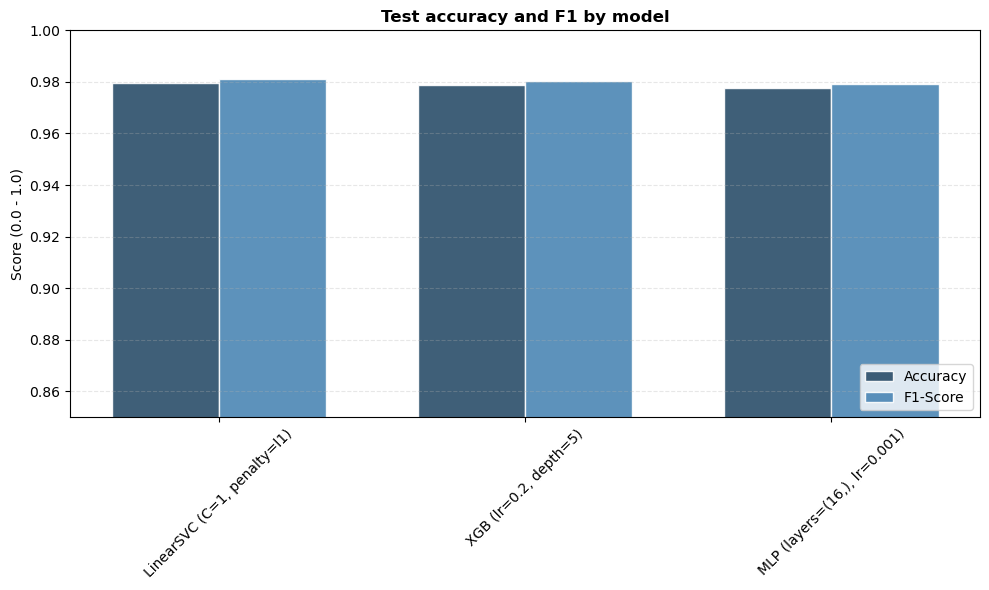

In [43]:
plt.figure(figsize=(10, 6))

plt.bar(x - width/2, df_stats['Accuracy'], width, label='Accuracy', color='#2a4d69', edgecolor='white', alpha=0.9)
plt.bar(x + width/2, df_stats['F1-Score'], width, label='F1-Score', color='#4b86b4', edgecolor='white', alpha=0.9)

plt.title('Test accuracy and F1 by model', fontweight='bold')
plt.ylabel('Score (0.0 - 1.0)')
plt.xticks(x, models, rotation=45)

plt.ylim(0.85, 1.0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
save_figure('test_accuracy_f1')
plt.show()

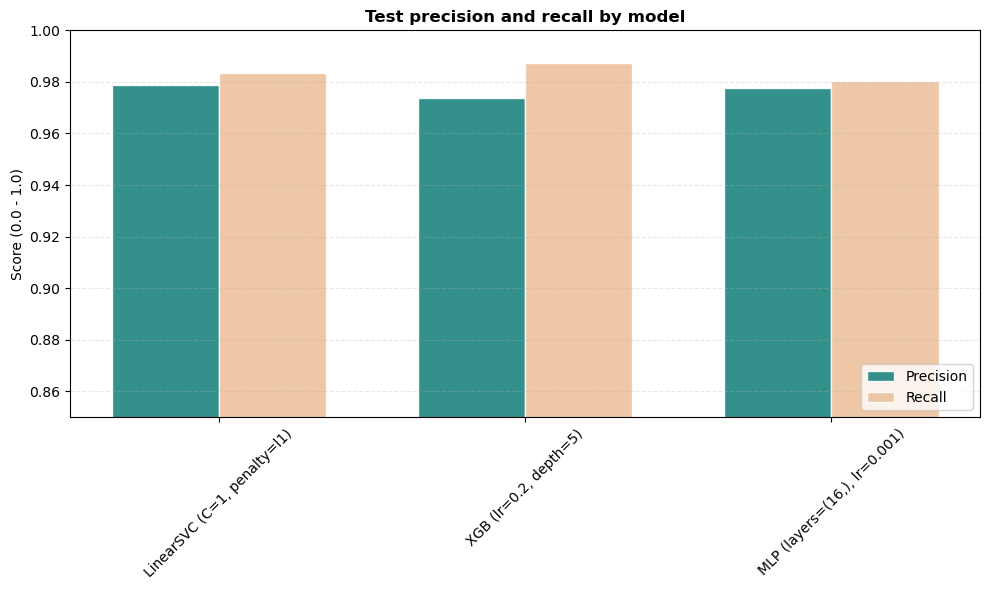

In [44]:
plt.figure(figsize=(10, 6))

plt.bar(x - width/2, df_stats['Precision'], width, label='Precision', color='#1e847f', edgecolor='white', alpha=0.9)
plt.bar(x + width/2, df_stats['Recall'], width, label='Recall', color='#ecc19c', edgecolor='white', alpha=0.9)

plt.title('Test precision and recall by model', fontweight='bold')
plt.ylabel('Score (0.0 - 1.0)')
plt.xticks(x, models, rotation=45)

plt.ylim(0.85, 1.0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
save_figure('test_precision_recall')
plt.show()

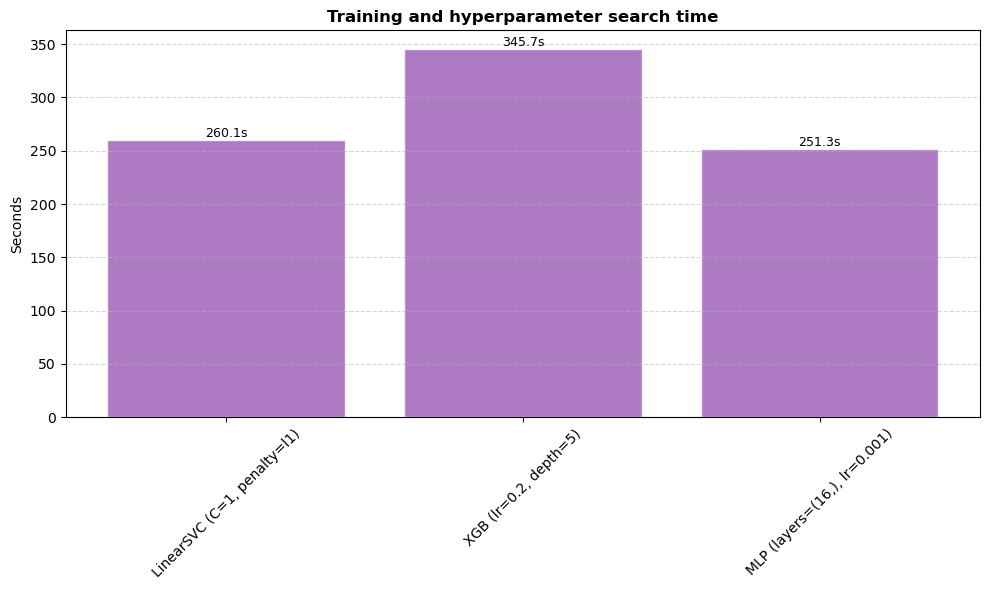

In [45]:
plt.figure(figsize=(10, 6))

plt.bar(models, df_stats['Time'], color='#9b59b6', alpha=0.8, edgecolor='white')

plt.title('Training and hyperparameter search time', fontweight='bold')
plt.ylabel('Seconds')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for i, v in enumerate(df_stats['Time']):
    plt.text(i, v + 0.1, f'{v:.1f}s', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
save_figure('training_time')
plt.show()

In [46]:
df_final = pd.DataFrame(model_stats).T
df_final = df_final.sort_values(by='Accuracy', ascending=False)

if 'Matrix' in df_final.columns:
    df_final = df_final.drop(columns=['Matrix'])

performance_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

final_table_styled = df_final.style.background_gradient(
    subset=performance_metrics,
    cmap='YlGn',
    axis=0
).background_gradient(
    subset=['Time'],
    cmap='RdYlGn_r',
    axis=0
).format(precision=4)

print("Test metrics by model")
display(final_table_styled)
df_final.to_csv(METRICS_DIR / 'test_metrics.csv')

Test metrics by model


,Accuracy,Precision,Recall,F1-Score,Time
"LinearSVC (C=1, penalty=l1)",0.9798,0.9790,0.9835,0.9812,260.0786
"XGB (lr=0.2, depth=5)",0.9788,0.9737,0.9873,0.9805,345.6643
"MLP (layers=(16,), lr=0.001)",0.9775,0.9778,0.9804,0.9791,251.3496


In [47]:
coefficients = best_svc.coef_[0]
feature_names = best_svc_pipeline.named_steps['tfidf'].get_feature_names_out()
top_fake = np.argsort(coefficients)[:10]
top_real = np.argsort(coefficients)[-10:]

print("\n*** Top 10 features associated with Fake ***")
for i in top_fake:
    print(f"- {feature_names[i]}")

print("\n*** Top 10 features associated with Real ***")
for i in top_real:
    print(f"- {feature_names[i]}")


*** Top 10 features associated with Fake ***
- featured image
- getty
- gop
- https
- read
- pic
- pic twitter
- hillary
- president trump
- apparently

*** Top 10 features associated with Real ***
- reuters
- wednesday
- monday
- tuesday
- friday
- rival
- hillary clinton
- nov
- president donald
- president barack


## Answer to RQ1: source and style cues

Fake-associated LinearSVC terms include `featured image`, `getty`, `https` and `pic twitter`. Real-associated terms include `reuters`, weekdays and political reporting phrases.

These coefficients connect the classifier to patterns observed in the EDA. The decision rule uses terms associated with source and format, which supports the shortcut-learning hypothesis. This analysis does not isolate the cause of the transfer gap.

## RQ2: custom headlines

The shared JSON contains 40 headlines: 20 synthetic examples assigned the Fake label and 20 headlines attributed to Reuters/AP News assigned Real. The file is checked against the reference texts and labels before evaluation.

This is an exploratory stress test. Source URLs and dates remain incomplete, and labels have not been independently verified. In particular, synthetic origin alone does not establish that a claim is false.

The full-text results include a change in input length. The following headline-only baseline uses titles during training as well as evaluation.

In [ ]:
EXPECTED_CUSTOM_COUNT = 40
with CUSTOM_PATH.open(encoding='utf-8') as handle:
    custom_records = json.load(handle)

if not isinstance(custom_records, list) or len(custom_records) != EXPECTED_CUSTOM_COUNT:
    found = len(custom_records) if isinstance(custom_records, list) else 'a non-list object'
    raise ValueError(
        f'Custom file: {CUSTOM_PATH.resolve()}. Found {found}; expected 40 records. '
        'Copy data/evaluation/custom_headlines.json from the repository to the same '
        'location under PROJECT_ROOT on Drive, then rerun this cell. Training does not need to be repeated.'
    )

expected_ids = {f'{prefix}_{i:02d}' for prefix in ['synthetic', 'reported'] for i in range(1, 21)}
if any(not isinstance(row, dict) or not {'id', 'text', 'label'} <= row.keys() for row in custom_records):
    raise ValueError('Each custom record must contain id, text and label. Copy the original JSON from the repository.')
if {row['id'] for row in custom_records} != expected_ids:
    raise ValueError('Custom record IDs differ from the shared 40-example set. Copy the original JSON from the repository.')
if any(not isinstance(row['text'], str) or not row['text'].strip() or row['label'] not in (0, 1) for row in custom_records):
    raise ValueError('Custom records require non-empty text and binary labels 0/1.')
if sum(row['label'] == 0 for row in custom_records) != 20:
    raise ValueError('The shared custom set must contain 20 Fake and 20 Real labels.')

import hashlib

EXPECTED_CUSTOM_SHA256 = '78afa2aff9c167ddfef84ae64ec4f8cab3febf6a74425d9ac37bd065024a882c'

def custom_fingerprint(records):
    values = [{'id': row['id'], 'text': row['text'], 'label': row['label']}
              for row in sorted(records, key=lambda row: row['id'])]
    payload = json.dumps(values, ensure_ascii=False, sort_keys=True, separators=(',', ':'))
    return hashlib.sha256(payload.encode('utf-8')).hexdigest()

def verify_custom_set(records):
    actual = custom_fingerprint(records)
    if actual != EXPECTED_CUSTOM_SHA256:
        raise ValueError(
            f'The custom headlines or labels in {CUSTOM_PATH.resolve()} differ from the shared benchmark. '
            'Copy the original data/evaluation/custom_headlines.json from the repository. '
            ''
            'Keep the trained model and rerun custom loading and inference.'
        )
    return actual

custom_dataset_sha256 = verify_custom_set(custom_records)

custom_sentences = [row['text'] for row in custom_records]
custom_labels = [row['label'] for row in custom_records]
print(f'Custom file: {CUSTOM_PATH.resolve()}')
print(f'Loaded {len(custom_records)} headlines: 20 Fake and 20 Real.')

print(f'Original benchmark verified: {custom_dataset_sha256[:12]}')

In [50]:
custom_df = pd.DataFrame({'text': custom_sentences})
custom_df['clean_data'] = custom_df['text'].apply(lemmatize_words).apply(clean_news_text)

In [51]:
def print_formatted_predictions(model_name, sentences, true_labels, preds, scores):
    print()
    print(f"{model_name} predictions:")
    print(
        f"{'Headline':<85} | "
        f"{'True':<5} | "
        f"{'Pred':<5} | "
        f"{'Confidence/Score'}"
    )
    print("-" * 125)

    for headline, true_label, pred, conf in zip(sentences, true_labels, preds, scores):
        true_name = "Real" if true_label == 1 else "Fake"
        pred_name = "Real" if pred == 1 else "Fake"

        print(
            f"{headline[:80]:<85} | "
            f"{true_name:<5} | "
            f"{pred_name:<5} | "
            f"{conf:.4f}"
        )

xgb_pred = best_xgb_pipeline.predict(custom_df['clean_data'])
xgb_proba = best_xgb_pipeline.predict_proba(custom_df['clean_data'])[:, 1]
print_formatted_predictions("XGBoost", custom_sentences, custom_labels, xgb_pred, xgb_proba)

svc_pred = best_svc_pipeline.predict(custom_df['clean_data'])
svc_decision = best_svc_pipeline.decision_function(custom_df['clean_data'])
print_formatted_predictions("LinearSVC", custom_sentences, custom_labels, svc_pred, svc_decision)

mlp_pred = best_mlp_pipeline.predict(custom_df['clean_data'])
mlp_proba = best_mlp_pipeline.predict_proba(custom_df['clean_data'])[:, 1]
print_formatted_predictions("MLP", custom_sentences, custom_labels, mlp_pred, mlp_proba)


XGBoost predictions:
Headline                                                                              | True  | Pred  | Confidence/Score
-----------------------------------------------------------------------------------------------------------------------------
President Donald said on Tuesday that talks with GOP officials were progressing       | Fake  | Real  | 0.6950
Hillary Clinton told Reuters on Wednesday that new proposals would be reviewed f      | Fake  | Real  | 0.8021
President Barack said on Thursday in a Reuters interview that long-term reforms       | Fake  | Real  | 0.9885
White House officials said on Monday that new sanctions against Iran would be de      | Fake  | Real  | 0.9219
Senate Republicans introduced a revised immigration proposal after overnight neg      | Fake  | Fake  | 0.3939
Federal Reserve officials discussed possible emergency measures following renewe      | Fake  | Fake  | 0.3927
U.S. officials told reporters that military advisers would remain

In [52]:
def calculate_custom_performance(y_true, y_pred):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, zero_division=0),
        recall_score(y_true, y_pred, zero_division=0),
        f1_score(y_true, y_pred, zero_division=0)
    ]

metrics_table = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'XGBoost': calculate_custom_performance(custom_labels, xgb_pred),
    'LinearSVC': calculate_custom_performance(custom_labels, svc_pred),
    'MLP (Neural Net)': calculate_custom_performance(custom_labels, mlp_pred)
}

df_summary = pd.DataFrame(metrics_table).set_index('Metric').transpose()

print("Custom headline metrics")
display(df_summary.style.format("{:.3f}").background_gradient(cmap='YlOrRd', axis=0))
df_summary.to_csv(METRICS_DIR / 'custom_metrics.csv')

Custom headline metrics


Metric,Accuracy,Precision,Recall,F1-Score
XGBoost,0.350,0.000,0.000,0.000
LinearSVC,0.450,0.438,0.350,0.389
MLP (Neural Net),0.350,0.312,0.250,0.278


## RQ3: headline-only baseline

LinearSVC trained on headlines reaches 91.95% internal accuracy and 57.5% custom accuracy, or 23 correct predictions out of 40. The drop is 34.45 percentage points, so matching input length does not remove the transfer problem.

On the custom set, recall is 25% for Fake and 90% for Real. The classifier predicts Real frequently and misses many examples assigned Fake. Notebook 2 uses this baseline to assess DistilBERT.

In [53]:
headline_text = df['lemmatized_title'].apply(clean_news_text)
headline_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=1000, max_df=0.5, ngram_range=(1, 2), stop_words='english')),
    ('model', LinearSVC(random_state=SEED, max_iter=2000, dual=False))
])
headline_search = GridSearchCV(headline_pipeline,
    {'model__C': [0.01, 0.1, 1, 10], 'model__penalty': ['l1', 'l2']},
    cv=3, scoring='accuracy', n_jobs=-1)
headline_search.fit(headline_text.loc[X_train.index], y_train)
headline_metrics = []
for partition, texts, labels in [
    ('test', headline_text.loc[X_test.index], y_test),
    ('custom', custom_df['clean_data'], custom_labels)
]:
    predicted = headline_search.predict(texts)
    headline_metrics.append({'partition': partition,
        'accuracy': accuracy_score(labels, predicted),
        'precision_real': precision_score(labels, predicted, zero_division=0),
        'recall_real': recall_score(labels, predicted, zero_division=0),
        'f1_real': f1_score(labels, predicted, zero_division=0),
        'macro_f1': f1_score(labels, predicted, average='macro', zero_division=0)})
headline_results = pd.DataFrame(headline_metrics)
headline_results.to_csv(METRICS_DIR / 'headline_svc_metrics.csv', index=False)
display(headline_results)

,partition,accuracy,precision_real,recall_real,f1_real,macro_f1
0,test,0.91955,0.917421,0.934511,0.925887,0.918957
1,custom,0.57500,0.545455,0.900000,0.679245,0.524808


## Conclusions

**RQ1.** Source markers, image credits, links and reporting vocabulary differ between the classes and appear in the fitted LinearSVC coefficients. These are plausible shortcuts associated with dataset construction.

**RQ2.** The full-text models fall from about 98% internal accuracy to 35-45% on the custom headlines. The headline-only baseline falls from 91.95% to 57.5%. High accuracy within this collection therefore gives an incomplete picture of transfer.

**RQ3.** The companion DistilBERT experiment reaches 75% on the same custom set, compared with 57.5% for headline-only LinearSVC. This is seven additional correct predictions. Notebook 2 examines the class-level results and remaining errors.

The comparison is exploratory: the custom sample is small and its labels need verification. Full-text models receive different information, while the two headline models also differ in preprocessing and model selection.

## Future work

- Use a dataset with more varied publishers, topics, periods and writing styles in both classes, including false claims written in a formal reporting style.
- Expand the external evaluation with documented sources and verified labels.
- Compare larger pretrained encoders under the same evaluation protocol, reporting computation time alongside accuracy.

The summary below reads the exported metric files.

In [ ]:
saved_test = pd.read_csv(METRICS_DIR / 'test_metrics.csv', index_col=0)
saved_custom = pd.read_csv(METRICS_DIR / 'custom_metrics.csv', index_col=0)
saved_headline = pd.read_csv(METRICS_DIR / 'headline_svc_metrics.csv').set_index('partition')
answer_rows = []
for prefix, custom_name in [('XGB', 'XGBoost'), ('LinearSVC', 'LinearSVC'), ('MLP', 'MLP (Neural Net)')]:
    internal = saved_test.loc[saved_test.index.str.startswith(prefix)].iloc[0]
    answer_rows.append({'model': custom_name, 'training input': 'title + body',
        'test accuracy': internal['Accuracy'],
        'custom accuracy': saved_custom.loc[custom_name, 'Accuracy']})
answer_rows.append({'model': 'LinearSVC headline baseline', 'training input': 'headline',
    'test accuracy': saved_headline.loc['test', 'accuracy'],
    'custom accuracy': saved_headline.loc['custom', 'accuracy']})
classical_comparison = pd.DataFrame(answer_rows)
classical_comparison['accuracy drop (percentage points)'] = 100 * (
    classical_comparison['test accuracy'] - classical_comparison['custom accuracy'])
display(classical_comparison.style.format({
    'test accuracy': '{:.2%}', 'custom accuracy': '{:.2%}',
    'accuracy drop (percentage points)': '{:.2f}'}))